# Local streaming performance

The accelerated run advances all event-time ticks. Scoring, collective scan overhead, daily closure, API response and browser display are different latency measurements. Results describe this specific Windows host and workload.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline')
import matplotlib.pyplot as plt
from IPython.display import display

root = Path.cwd()
if not (root / 'config' / 'live_monitoring.v1.json').exists():
    root = root.parent
evidence = root / 'reports' / 'live_monitoring'
figures = evidence / 'figures'
figures.mkdir(exist_ok=True)
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .2, 'figure.dpi': 110})

def save(fig, name):
    fig.tight_layout()
    fig.savefig(figures / (name + '.png'), dpi=140, bbox_inches='tight')
    display(fig)
    plt.close(fig)


,Measured value
events,5.090000e+02
bins,2.880000e+02
total_seconds,7.828516e+00
events_per_second,6.501871e+01
max_tick_ms,1.491420e+01
p95_tick_ms,1.095725e+01
median_scoring_tick_ms,6.980700e+00
median_tick_with_collective_ms,8.794500e+00
closing_tick_ms,5.607387e+03
process_rss_bytes,1.890345e+08


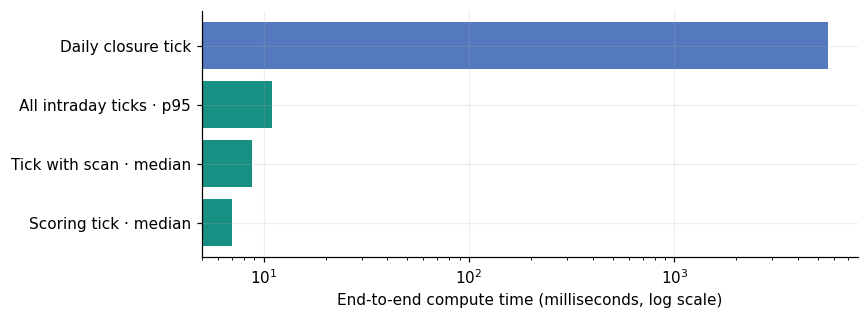

,Chromium verification
status,passed
environment,"Windows, Chromium, Next.js production build an..."
first_plot_ms,832
warm_snapshot_ms,21
collective_warnings,1
resolved_warnings,1
assistant,deterministic fallback
follow_up,"{'status': 'passed', 'first_plot_ms': 848, 'wa..."
existing_regression,"{'status': 'passed', 'checks': 'Existing brows..."
checks,"[authentication, cross-site write rejection, s..."


In [2]:
m = json.loads((evidence / 'performance.json').read_text())
display(pd.Series(m, name='Measured value').to_frame())
fig, ax = plt.subplots(figsize=(8, 3))
latencies = {'Scoring tick · median': m['median_scoring_tick_ms'],
             'Tick with scan · median': m['median_tick_with_collective_ms'],
             'All intraday ticks · p95': m['p95_tick_ms'],
             'Daily closure tick': m['closing_tick_ms']}
ax.barh(list(latencies), list(latencies.values()), color=['#178f82']*3 + ['#5479bf'])
ax.set(xlabel='End-to-end compute time (milliseconds, log scale)', xscale='log')
save(fig, 'streaming_latency')
browser = evidence / 'browser_verification.json'
if browser.exists():
    display(pd.Series(json.loads(browser.read_text()), name='Chromium verification').to_frame())
